# Clustering V1

For this first clustering experiment, I used k-Means on 1000 sentiment samples with 3 clusters. I wanted to see whether the examples would naturally form groups that match their sentiment labels.

First, I imported the libraries and functions I'll need.

In [1]:
from pathlib import Path
from time import perf_counter
from collections import Counter
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.data_loader import load_task
from src.models.clustering import KMeans


I started by randomly selecting 1000 sentiment samples.

In [2]:
X_train, y_train, _, _ = load_task("sentiment")
assert X_train.shape == (12000, 768)
rng = np.random.default_rng(42)
indices = rng.choice(len(X_train), size=1000, replace=False)
X_subset = X_train[indices]
y_subset = y_train[indices]
assert len(np.unique(indices)) == 1000
print(f"Selected {len(X_subset)} samples with {X_subset.shape[1]} features")


Selected 1000 samples with 768 features


Then I ran k-Means with 3 clusters.

In [3]:
km = KMeans(k=3, max_iter=100, tol=1e-4, seed=42)
start = perf_counter()
km.fit(X_subset)
fit_time = perf_counter() - start
cluster_sizes = Counter(km.labels_)
print(f"Samples: {len(X_subset)}")
print(f"Features: {X_subset.shape[1]}")
print(f"k: {km.k}")
print(f"Iterations: {km.n_iter_}")
print(f"Inertia: {km.inertia_:.6f}")
print(f"Fitting time: {fit_time:.6f} s")
for cluster in range(km.k):
    print(f"Cluster {cluster}: {cluster_sizes[cluster]} samples")


Samples: 1000
Features: 768
k: 3
Iterations: 19
Inertia: 26325.122315
Fitting time: 1.360252 s
Cluster 0: 400 samples
Cluster 1: 266 samples
Cluster 2: 334 samples


I compared the clusters with the actual sentiment labels to see how the samples were grouped.

In [4]:
def cluster_purity(labels_pred, labels_true):
    correct = 0
    for cluster_id in set(labels_pred):
        true_in_cluster = [labels_true[i] for i in range(len(labels_pred))
                           if labels_pred[i] == cluster_id]
        correct += Counter(true_in_cluster).most_common(1)[0][1]
    return correct / len(labels_pred)

count_rows = []
for cluster in range(km.k):
    true_in_cluster = [y_subset[i] for i in range(len(y_subset))
                       if km.labels_[i] == cluster]
    counts = Counter(true_in_cluster)
    count_rows.append({
        "cluster": cluster,
        "negative": counts[0],
        "neutral": counts[1],
        "positive": counts[2],
        "total": len(true_in_cluster),
    })
cluster_counts = pd.DataFrame(count_rows)
purity = cluster_purity(km.labels_, y_subset)
assert cluster_counts["total"].sum() == 1000
assert cluster_counts[["negative", "neutral", "positive"]].to_numpy().sum() == 1000
assert 0 <= purity <= 1
print("Cluster numbers are arbitrary IDs, not sentiment classes.")
print(cluster_counts.to_string(index=False))
print(f"Cluster purity: {purity:.4f}")


Cluster numbers are arbitrary IDs, not sentiment classes.
 cluster  negative  neutral  positive  total
       0       122      134       144    400
       1        81      123        62    266
       2       114      100       120    334
Cluster purity: 0.3870


I plotted the cluster sizes to compare them.

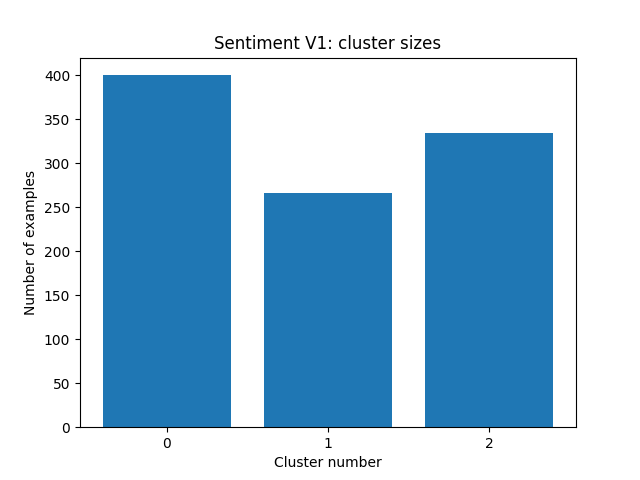

In [5]:
result_dir = project_root / "results" / "clustering"
result_dir.mkdir(parents=True, exist_ok=True)
plt.figure()
plt.bar([str(cluster) for cluster in cluster_counts["cluster"]], cluster_counts["total"])
plt.xlabel("Cluster number")
plt.ylabel("Number of examples")
plt.title("Sentiment V1: cluster sizes")
plt.savefig(result_dir / "clustering_v1_cluster_sizes.png")
plt.show()


Finally, I saved the results so I can compare them with the next experiments.

In [6]:
summary = pd.DataFrame([{
    "version": "V1",
    "dataset": "sentiment",
    "samples": len(X_subset),
    "features": X_subset.shape[1],
    "k": km.k,
    "seed": km.seed,
    "max_iter": km.max_iter,
    "iterations": km.n_iter_,
    "inertia": km.inertia_,
    "purity": purity,
    "fit_time_seconds": fit_time,
}])
summary.to_csv(result_dir / "clustering_v1_summary.csv", index=False)
assignments = pd.DataFrame({
    "original_row_index": indices,
    "true_label": y_subset,
    "cluster": km.labels_,
})
assignments.to_csv(result_dir / "clustering_v1_assignments.csv", index=False)
cluster_counts.to_csv(result_dir / "clustering_v1_cluster_counts.csv", index=False)
print(summary.to_string(index=False))
print("Saved the summary, assignments and cluster counts in", result_dir)


version   dataset  samples  features  k  seed  max_iter  iterations      inertia  purity  fit_time_seconds
     V1 sentiment     1000       768  3    42       100          19 26325.122315   0.387          1.360252
Saved the summary, assignments and cluster counts in C:\Users\user\OneDrive\Documentos\Fall2026\COMP472\team_project\COMP472\results\clustering
